# Preskriptívna údržba: opatrenia na základe predikcie závažnosti

Notebook nadväzuje na `predikcia.ipynb`. Predikcia odpovedá na otázku, aká závažná je nová zraniteľnosť. Tento notebook odpovedá na otázku, **čo s ňou urobiť a dokedy**.

| | |
| --- | --- |
| **Vstup** | `data/processed/cve_clean.csv`, LightGBM s parametrami vybranými v `predikcia.ipynb` |
| **Opatrenia** | 4 typy: monitorovanie, plánovaná oprava, dočasná ochrana s prioritnou opravou, núdzová oprava |
| **Zohľadnené faktory** | riziko, náklady, čas a priorita |
| **Vyhodnotenie** | zraniteľnosti z rokov 2020 a 2021, porovnanie s pevnými stratégiami |
| **Výstup** | `data/processed/odporucania_opatreni.csv`, `figures/7_prahy_opatreni.png`, `figures/8_opatrenia_podla_zavaznosti.png`, `figures/9_porovnanie_strategii.png` |

**Postup.** Model odhadne pravdepodobnosť každej triedy závažnosti. Pre každé opatrenie sa z nej vypočítajú očakávané celkové náklady, teda práca plus škoda hroziaca počas času, keď je zraniteľnosť otvorená. Odporučí sa opatrenie s najnižšími očakávanými nákladmi.

In [1]:
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import sparse
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss

DATA_PATH = Path("data/processed/cve_clean.csv")
OUTPUT_PATH = Path("data/processed/odporucania_opatreni.csv")
FIGURES_DIR = Path("figures")
LABELS = ["LOW", "MEDIUM", "HIGH", "CRITICAL"]
CRITICAL = LABELS.index("CRITICAL")
SEED = 42

# Rovnaké vylúčenie úniku cieľa ako v predikcia.ipynb
LEAKAGE_PATTERN = (
    r"\bcvss(?:v?\d|:|\b)"
    r"|base score"
    r"|severity"
    r"|\brated\s+(?:as\s+)?(?:critical|high|moderate|medium|low)\b"
)

scored = pd.read_csv(DATA_PATH).dropna(subset=["severity_v3"])
has_leakage = scored["description"].str.contains(LEAKAGE_PATTERN, case=False, regex=True)
data = scored[~has_leakage].reset_index(drop=True)
data["cwe_text"] = data["cwe_ids"].fillna("")
data["target"] = pd.Categorical(data["severity_v3"], categories=LABELS, ordered=True).codes
assert data["target"].between(0, 3).all()

train = data[data["year"] <= 2018]
calibration = data[data["year"] == 2019]
test = data[data["year"] >= 2020].reset_index(drop=True)
y_test = test["target"].to_numpy()
print(f"Tréning: {len(train)}, kalibrácia: {len(calibration)}, test: {len(test)}")

Tréning: 41890, kalibrácia: 14751, test: 32050


## 1. Pravdepodobnosti z modelu

Rozhodovanie potrebuje **pravdivé pravdepodobnosti**, nielen najpravdepodobnejšiu triedu. Model z `predikcia.ipynb` používa `class_weight="balanced"`, ktorý zámerne nadhodnocuje zriedkavé triedy. Preto sa pravdepodobnosti kalibrujú.

| Množina | Roky v CVE-ID | Použitie |
| --- | --- | --- |
| Tréningová | do 2018 | učenie LightGBM |
| Kalibračná | 2019 | oprava pravdepodobností multinomickou logistickou regresiou |
| Testovacia | 2020 a 2021 | jednorazové vyhodnotenie opatrení |

Model sa tu učí iba na dátach do roku 2018, lebo rok 2019 musí zostať pre kalibráciu nevidený. Parametre (63 listov, 118 stromov) pochádzajú z výberu v `predikcia.ipynb`.

In [2]:
features = ColumnTransformer([
    ("text", TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2),
        min_df=5,
        max_df=0.9,
        max_features=30_000,
        sublinear_tf=True,
    ), "description"),
    ("cwe", CountVectorizer(
        lowercase=False,
        token_pattern=r"CWE-\d+",
        binary=True,
    ), "cwe_text"),
])

def to_float32(matrix):
    return sparse.csr_matrix(matrix, dtype=np.float32)

X_train = to_float32(features.fit_transform(train))
X_calibration = to_float32(features.transform(calibration))
X_test = to_float32(features.transform(test))

model = lgb.LGBMClassifier(
    objective="multiclass",
    class_weight="balanced",
    n_estimators=118,
    learning_rate=0.1,
    num_leaves=63,
    min_child_samples=20,
    colsample_bytree=0.3,
    subsample=0.8,
    subsample_freq=1,
    random_state=SEED,
    deterministic=True,
    force_row_wise=True,
    n_jobs=4,
    verbosity=-1,
)
model.fit(X_train, train["target"].to_numpy())

def log_probabilities(X):
    return np.log(np.clip(model.predict_proba(X), 1e-6, 1))

calibrator = LogisticRegression(C=1e4, max_iter=5000)
calibrator.fit(log_probabilities(X_calibration), calibration["target"].to_numpy())

P_raw = model.predict_proba(X_test)
P_calibrated = calibrator.predict_proba(log_probabilities(X_test))

print(f"Log loss bez kalibrácie: {log_loss(y_test, P_raw, labels=[0, 1, 2, 3]):.4f}")
print(f"Log loss po kalibrácii:  {log_loss(y_test, P_calibrated, labels=[0, 1, 2, 3]):.4f}")

Log loss bez kalibrácie: 0.8370
Log loss po kalibrácii:  0.7739


Kontrola kalibrácie: v každom pásme by mal priemerný odhad `P(CRITICAL)` približne zodpovedať skutočnému podielu kritických zraniteľností.

In [3]:
def reliability(probabilities):
    bins = pd.cut(probabilities[:, CRITICAL], [0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1], include_lowest=True)
    return pd.DataFrame({"p": probabilities[:, CRITICAL], "critical": y_test == CRITICAL}).groupby(bins, observed=True).agg(
        počet=("p", "size"), priemerný_odhad=("p", "mean"), skutočný_podiel=("critical", "mean")
    ).round(3)

print("Bez kalibrácie:")
display(reliability(P_raw))
print("Po kalibrácii:")
display(reliability(P_calibrated))

Bez kalibrácie:


,počet,priemerný_odhad,skutočný_podiel
"(-0.001, 0.05]",11672,0.015,0.012
"(0.05, 0.1]",3674,0.073,0.034
"(0.1, 0.2]",4316,0.145,0.069
"(0.2, 0.3]",2893,0.246,0.134
"(0.3, 0.5]",3849,0.393,0.210
"(0.5, 0.75]",3277,0.620,0.381
"(0.75, 1.0]",2369,0.853,0.594


Po kalibrácii:


,počet,priemerný_odhad,skutočný_podiel
"(-0.001, 0.05]",13579,0.014,0.014
"(0.05, 0.1]",4184,0.074,0.051
"(0.1, 0.2]",4907,0.146,0.119
"(0.2, 0.3]",2985,0.247,0.188
"(0.3, 0.5]",3526,0.389,0.335
"(0.5, 0.75]",2594,0.608,0.574
"(0.75, 1.0]",275,0.786,0.716


## 2. Typy opatrení a predpoklady

Navrhujeme štyri typy opatrení, zoradené od najmenej po najviac naliehavé:

| Opatrenie | Čo sa vykoná | Práca | Čas |
| --- | --- | ---: | --- |
| **Monitorovanie** | sledovanie výskytu a zneužitia, oprava pri bežnej údržbe | 1 h | oprava do 90 dní |
| **Plánovaná oprava** | zaradenie do mesačného cyklu záplat, bežné testovanie | 4 h | oprava do 30 dní |
| **Dočasná ochrana a prioritná oprava** | pravidlo WAF, obmedzenie prístupu alebo izolácia, potom oprava | 10 h | ochrana do 2 dní, oprava do 14 dní |
| **Núdzová oprava** | mimoriadna zmena mimo cyklu, zrýchlené testovanie, nasadenie | 16 h | oprava do 3 dní |

**Dôležité obmedzenie.** Dataset neobsahuje náklady, čas ani skutočné zneužitia. Hodnoty nižšie sú preto **predpoklady pre modelovú organizáciu**, nie merania. Boli stanovené pred vyhodnotením a na testovacích dátach sa neladili. Časť 6 overuje, čo sa stane, keď sa zmenia. Pri reálnom nasadení ich treba nahradiť údajmi organizácie, napríklad hodnotou aktív a pravdepodobnosťou zneužitia z EPSS.

In [4]:
HOURLY_RATE = 60

SEVERITY_ASSUMPTIONS = pd.DataFrame({
    "škoda pri zneužití (€)": [1_000, 10_000, 50_000, 200_000],
    "pravdepodobnosť zneužitia za 90 dní": [0.005, 0.01, 0.03, 0.08],
}, index=LABELS)

ACTION_NAMES = ["Monitorovanie", "Plánovaná oprava", "Dočasná ochrana", "Núdzová oprava"]
ACTION_ASSUMPTIONS = pd.DataFrame({
    "hodiny práce": [1, 4, 10, 16],
    "dni do ochrany": [90, 30, 2, 3],
    "dni do opravy": [90, 30, 14, 3],
}, index=ACTION_NAMES)
PROTECTION_RESIDUAL = 0.3  # podiel rizika, ktorý zostáva po nasadení dočasnej ochrany

def scenario(damage=1.0, exploit=1.0, labor=1.0, residual=PROTECTION_RESIDUAL):
    """Vráti náklady opatrení, efektívne dni expozície a dennú očakávanú škodu tried."""
    hours = ACTION_ASSUMPTIONS["hodiny práce"].to_numpy(dtype=float)
    protect = ACTION_ASSUMPTIONS["dni do ochrany"].to_numpy(dtype=float)
    fix = ACTION_ASSUMPTIONS["dni do opravy"].to_numpy(dtype=float)
    daily = (
        SEVERITY_ASSUMPTIONS["škoda pri zneužití (€)"].to_numpy(dtype=float)
        * SEVERITY_ASSUMPTIONS["pravdepodobnosť zneužitia za 90 dní"].to_numpy(dtype=float)
        / 90 * damage * exploit
    )
    return hours * HOURLY_RATE * labor, protect + (fix - protect) * residual, daily

COST, EXPOSURE, DAILY_RISK = scenario()

display(SEVERITY_ASSUMPTIONS.assign(**{"denná očakávaná škoda (€)": DAILY_RISK.round(2)}))
display(ACTION_ASSUMPTIONS.assign(**{"náklady na prácu (€)": COST, "efektívne dni expozície": EXPOSURE}))

,škoda pri zneužití (€),pravdepodobnosť zneužitia za 90 dní,denná očakávaná škoda (€)
LOW,1000,0.005,0.06
MEDIUM,10000,0.010,1.11
HIGH,50000,0.030,16.67
CRITICAL,200000,0.080,177.78


,hodiny práce,dni do ochrany,dni do opravy,náklady na prácu (€),efektívne dni expozície
Monitorovanie,1,90,90,60.0,90.0
Plánovaná oprava,4,30,30,240.0,30.0
Dočasná ochrana,10,2,14,600.0,5.6
Núdzová oprava,16,3,3,960.0,3.0


**Ako faktory vstupujú do rozhodnutia:**

- **Riziko** je denná očakávaná škoda. Vážime ju pravdepodobnosťami z modelu: `r = Σ P(trieda) · denná škoda triedy`.
- **Čas** je počet efektívnych dní expozície. Dni po nasadení dočasnej ochrany sa rátajú len z 30 %.
- **Náklady** sú hodiny práce krát hodinová sadzba.
- **Priorita** je poradie v rámci frontu podľa `r`, takže pri nedostatku kapacity sa rieši najprv najväčšie riziko.

Pre opatrenie `a` platí: `očakávané náklady(a) = práca(a) + expozícia(a) · r`. Odporučí sa opatrenie s najnižšou hodnotou.

Vzťah je v `r` lineárny, takže rozhodnutie sa dá vyjadriť jednoduchými prahmi. Opatrenie sa oplatí zmeniť za naliehavejšie vtedy, keď ušetrené riziko prevýši dodatočnú prácu.

In [5]:
def break_even_points(cost, exposure):
    """Prahy r, pri ktorých sa mení najlacnejšie opatrenie (dolná obálka priamok)."""
    points, current = [], 0
    r = 0.0
    while current < len(cost) - 1:
        candidates = [
            ((cost[j] - cost[current]) / (exposure[current] - exposure[j]), j)
            for j in range(current + 1, len(cost))
            if exposure[j] < exposure[current]
        ]
        r, current_next = min(candidates)
        points.append((ACTION_NAMES[current], ACTION_NAMES[current_next], r))
        current = current_next
    return points

thresholds = pd.DataFrame(break_even_points(COST, EXPOSURE), columns=["z opatrenia", "na opatrenie", "prah r (€ za deň)"]).round(2)
display(thresholds)

,z opatrenia,na opatrenie,prah r (€ za deň)
0,Monitorovanie,Plánovaná oprava,3.00
1,Plánovaná oprava,Dočasná ochrana,14.75
2,Dočasná ochrana,Núdzová oprava,138.46


## 3. Odporúčané opatrenia

In [6]:
def decide(probabilities, cost=COST, exposure=EXPOSURE, daily=DAILY_RISK):
    expected_risk = probabilities @ daily
    return (cost[None, :] + exposure[None, :] * expected_risk[:, None]).argmin(axis=1)

def realized_loss(decisions, cost=COST, exposure=EXPOSURE, daily=DAILY_RISK):
    return cost[decisions] + exposure[decisions] * daily[y_test]

decision = decide(P_calibrated)
expected_risk = P_calibrated @ DAILY_RISK

recommendations = test[["cve_id", "year", "severity_v3", "cwe_text", "description"]].copy()
recommendations["P_CRITICAL"] = P_calibrated[:, CRITICAL]
recommendations["ocakavane_denne_riziko"] = expected_risk
recommendations["opatrenie"] = np.array(ACTION_NAMES)[decision]

summary = recommendations.groupby("opatrenie").agg(
    počet=("cve_id", "size"),
    priemer_P_CRITICAL=("P_CRITICAL", "mean"),
    priemer_r=("ocakavane_denne_riziko", "mean"),
    skutočne_CRITICAL=("severity_v3", lambda s: (s == "CRITICAL").mean()),
    skutočne_HIGH=("severity_v3", lambda s: (s == "HIGH").mean()),
).reindex(ACTION_NAMES)
summary["podiel %"] = (summary["počet"] / len(test) * 100).round(1)
summary["hodiny práce spolu"] = summary["počet"] * ACTION_ASSUMPTIONS["hodiny práce"]
display(summary.round(3))

action_by_truth = pd.crosstab(test["severity_v3"], recommendations["opatrenie"], normalize="index").reindex(index=LABELS, columns=ACTION_NAMES).fillna(0)
display(action_by_truth.mul(100).round(1))

,počet,priemer_P_CRITICAL,priemer_r,skutočne_CRITICAL,skutočne_HIGH,podiel %,hodiny práce spolu
opatrenie,,,,,,,
Monitorovanie,4249,0.001,1.615,0.009,0.017,13.3,4249
Plánovaná oprava,6331,0.017,9.166,0.016,0.288,19.8,25324
Dočasná ochrana,21237,0.227,49.731,0.194,0.555,66.3,212370
Núdzová oprava,233,0.791,143.851,0.704,0.283,0.7,3728


opatrenie,Monitorovanie,Plánovaná oprava,Dočasná ochrana,Núdzová oprava
severity_v3,,,,
LOW,5.5,41.9,52.5,0.0
MEDIUM,31.0,31.2,37.8,0.0
HIGH,0.5,13.3,85.7,0.5
CRITICAL,0.9,2.4,93.1,3.7


### Príklady odporúčaní

In [7]:
with pd.option_context("display.max_colwidth", 90):
    sample = recommendations.groupby("opatrenie", group_keys=False).sample(2, random_state=SEED)
    sample = sample.assign(popis=sample["description"].str.slice(0, 85), P_CRITICAL=sample["P_CRITICAL"].round(2))
    display(sample.sort_values("P_CRITICAL")[["cve_id", "opatrenie", "P_CRITICAL", "severity_v3", "cwe_text", "popis"]])

,cve_id,opatrenie,P_CRITICAL,severity_v3,cwe_text,popis
7702,CVE-2020-22790,Monitorovanie,0.00,MEDIUM,CWE-79,Authenticated Stored XSS in FME Server versions 2019.2 and 2020.0 Beta allows a remot
21912,CVE-2021-24834,Monitorovanie,0.00,MEDIUM,CWE-79,The YOP Poll WordPress plugin before 6.3.1 is affected by a stored Cross-Site Scripti
19013,CVE-2021-20626,Plánovaná oprava,0.01,MEDIUM,CWE-863,Improper access control vulnerability in Workflow of Cybozu Office 10.0.0 to 10.8.4 a
17248,CVE-2021-0352,Plánovaná oprava,0.02,MEDIUM,CWE-843,"In RT regmap driver, there is a possible memory corruption due to type confusion. Thi"
13988,CVE-2020-6109,Dočasná ochrana,0.10,CRITICAL,CWE-22,"An exploitable path traversal vulnerability exists in the Zoom client, version 4.6.10"
9581,CVE-2020-26973,Dočasná ochrana,0.63,HIGH,,"Certain input to the CSS Sanitizer confused it, resulting in incorrect components bei"
17785,CVE-2021-1139,Núdzová oprava,0.77,HIGH,CWE-20,Multiple vulnerabilities in the web UI of Cisco Smart Software Manager Satellite coul
2258,CVE-2020-11518,Núdzová oprava,0.78,CRITICAL,,Zoho ManageEngine ADSelfService Plus before 5815 allows unauthenticated remote code e


### Konkrétna podoba dočasnej ochrany podľa typu slabiny

Dočasná ochrana závisí od typu slabiny. Tabuľka uvádza najčastejšie typy CWE v tomto fronte a vhodný zásah.

In [8]:
CONTROLS = {
    "CWE-79": "pravidlo WAF, prísna Content-Security-Policy",
    "CWE-89": "pravidlo WAF, obmedzenie práv databázového účtu",
    "CWE-20": "filtrovanie vstupov na proxy alebo WAF",
    "CWE-22": "pravidlo WAF, obmedzenie práv k súborom",
    "CWE-78": "izolácia služby, spustenie s minimálnymi právami",
    "CWE-77": "izolácia služby, spustenie s minimálnymi právami",
    "CWE-94": "izolácia služby, zákaz odchádzajúcich spojení",
    "CWE-119": "obmedzenie sieťového prístupu, izolácia procesu",
    "CWE-120": "obmedzenie sieťového prístupu, izolácia procesu",
    "CWE-125": "obmedzenie sieťového prístupu, izolácia procesu",
    "CWE-787": "obmedzenie sieťového prístupu, izolácia procesu",
    "CWE-416": "obmedzenie sieťového prístupu, izolácia procesu",
    "CWE-190": "obmedzenie sieťového prístupu, izolácia procesu",
    "CWE-287": "prístup iba cez VPN, viacfaktorové overenie",
    "CWE-306": "prístup iba cez VPN, viacfaktorové overenie",
    "CWE-798": "zmena prihlasovacích údajov, prístup iba cez VPN",
    "CWE-269": "obmedzenie účtov, sledovanie zmien oprávnení",
    "CWE-284": "dočasné sprísnenie prístupových pravidiel",
    "CWE-862": "dočasné sprísnenie prístupových pravidiel",
    "CWE-863": "dočasné sprísnenie prístupových pravidiel",
    "CWE-200": "obmedzenie prístupu k službe, sledovanie prístupov",
    "CWE-352": "kontrola pôvodu požiadaviek na proxy, SameSite cookies",
    "CWE-434": "dočasný zákaz nahrávania súborov",
    "CWE-502": "obmedzenie sieťového prístupu k službe",
    "CWE-400": "obmedzenie počtu požiadaviek",
}

protected = recommendations[recommendations["opatrenie"] == "Dočasná ochrana"]
top_cwe = protected["cwe_text"].str.findall(r"CWE-\d+").explode().dropna().value_counts().head(10).to_frame("počet")
top_cwe["podiel frontu %"] = (top_cwe["počet"] / len(protected) * 100).round(1)
top_cwe["dočasná ochrana"] = top_cwe.index.map(CONTROLS).fillna("posúdiť individuálne")
with pd.option_context("display.max_colwidth", 80):
    display(top_cwe)

,počet,podiel frontu %,dočasná ochrana
cwe_text,,,
CWE-787,2155,10.1,"obmedzenie sieťového prístupu, izolácia procesu"
CWE-89,929,4.4,"pravidlo WAF, obmedzenie práv databázového účtu"
CWE-125,838,3.9,"obmedzenie sieťového prístupu, izolácia procesu"
CWE-20,826,3.9,filtrovanie vstupov na proxy alebo WAF
CWE-416,761,3.6,"obmedzenie sieťového prístupu, izolácia procesu"
CWE-269,758,3.6,"obmedzenie účtov, sledovanie zmien oprávnení"
CWE-78,633,3.0,"izolácia služby, spustenie s minimálnymi právami"
CWE-22,626,2.9,"pravidlo WAF, obmedzenie práv k súborom"
CWE-120,547,2.6,"obmedzenie sieťového prístupu, izolácia procesu"


## 4. Porovnanie stratégií

Každá stratégia sa vyhodnocuje podľa **skutočnej** závažnosti zo CVSS v3. Výsledok je priemer na jednu zraniteľnosť: práca plus škoda počas expozície.

Pevné stratégie uplatňujú rovnaké opatrenie na všetko. Stratégia *Podľa predikovanej triedy* mapuje triedu priamo na opatrenie, teda `LOW` na monitorovanie až `CRITICAL` na núdzovú opravu. Stratégia *S dokonalou znalosťou* pozná skutočnú závažnosť a je iba teoretickou hranicou.

In [9]:
STRATEGY_OURS = "Podľa očakávaných nákladov"
one_hot = np.eye(4)[y_test]

strategies = {name: np.full(len(test), index) for index, name in enumerate(ACTION_NAMES)}
strategies["Podľa predikovanej triedy"] = P_raw.argmax(axis=1)
strategies["Očakávané náklady bez kalibrácie"] = decide(P_raw)
strategies[STRATEGY_OURS] = decision
strategies["S dokonalou znalosťou"] = decide(one_hot)

def describe_strategy(chosen):
    labor = COST[chosen].mean()
    damage = (EXPOSURE[chosen] * DAILY_RISK[y_test]).mean()
    critical = y_test == CRITICAL
    return {
        "práca (€)": labor,
        "škoda počas expozície (€)": damage,
        "spolu (€)": labor + damage,
        "CRITICAL chránené do 3 dní %": np.isin(chosen[critical], [2, 3]).mean() * 100,
        "CRITICAL iba monitorované %": (chosen[critical] == 0).mean() * 100,
    }

comparison = pd.DataFrame({name: describe_strategy(chosen) for name, chosen in strategies.items()}).T.sort_values("spolu (€)")
display(comparison.round(1))

,práca (€),škoda počas expozície (€),spolu (€),CRITICAL chránené do 3 dní %,CRITICAL iba monitorované %
S dokonalou znalosťou,415.7,154.9,570.7,100.0,0.0
Podľa očakávaných nákladov,459.9,251.6,711.5,96.8,0.9
Očakávané náklady bez kalibrácie,501.7,217.8,719.5,97.7,0.8
Podľa predikovanej triedy,546.0,218.9,764.8,92.4,0.3
Dočasná ochrana,600.0,179.9,779.9,100.0,0.0
Núdzová oprava,960.0,96.4,1056.4,100.0,0.0
Plánovaná oprava,240.0,963.8,1203.8,0.0,0.0
Monitorovanie,60.0,2891.3,2951.3,0.0,100.0


In [10]:
rng = np.random.default_rng(SEED)
fixed_names = ACTION_NAMES
best_fixed = comparison.loc[fixed_names, "spolu (€)"].idxmin()
ours = realized_loss(decision)

def bootstrap_saving(baseline_name, repeats=2000):
    baseline = realized_loss(strategies[baseline_name])
    differences = baseline - ours
    samples = [
        differences[rng.integers(0, len(differences), len(differences))].mean()
        for _ in range(repeats)
    ]
    low, high = np.percentile(samples, [2.5, 97.5])
    return {
        "úspora (€ na CVE)": differences.mean(),
        "úspora %": differences.mean() / baseline.mean() * 100,
        "95 % interval od": low,
        "95 % interval do": high,
    }

print("Najlepšia pevná stratégia:", best_fixed)
pd.DataFrame({
    name: bootstrap_saving(name)
    for name in [best_fixed, "Podľa predikovanej triedy", "Očakávané náklady bez kalibrácie"]
}).T.round(2)

Najlepšia pevná stratégia: Dočasná ochrana


,úspora (€ na CVE),úspora %,95 % interval od,95 % interval do
Dočasná ochrana,68.39,8.77,61.66,74.69
Podľa predikovanej triedy,53.32,6.97,47.05,59.54
Očakávané náklady bez kalibrácie,7.95,1.11,5.60,10.26


## 5. Priorita pri obmedzenej kapacite

Tím nestihne všetko naraz. Ak sa zraniteľnosti riešia v poradí podľa `r`, malá časť frontu pokryje neúmerne veľkú časť kritických prípadov. *Násobok* hovorí, koľkokrát je výsledok lepší než náhodné poradie.

In [11]:
order = np.argsort(-expected_risk, kind="stable")
is_critical = (y_test == CRITICAL)[order]

rows = []
for share in [0.05, 0.10, 0.20, 0.30, 0.50]:
    top = int(len(order) * share)
    captured = is_critical[:top].sum() / is_critical.sum()
    rows.append({
        "riešený podiel %": int(share * 100),
        "počet CVE": top,
        "zachytené CRITICAL %": round(captured * 100, 1),
        "podiel CRITICAL vo výbere %": round(is_critical[:top].mean() * 100, 1),
        "násobok oproti náhode": round(captured / share, 2),
    })
priority_table = pd.DataFrame(rows)
priority_table

,riešený podiel %,počet CVE,zachytené CRITICAL %,podiel CRITICAL vo výbere %,násobok oproti náhode
0,5,1602,23.2,64.0,4.64
1,10,3205,41.3,56.9,4.13
2,20,6410,65.0,44.8,3.25
3,30,9615,78.1,35.9,2.60
4,50,16025,92.9,25.6,1.86


## 6. Citlivosť na predpoklady

Predpoklady sú odhadnuté, preto meníme každý z nich a sledujeme, či odporúčanie obstojí. Politika sa v každom scenári prepočíta z tých istých pravdepodobností modelu. Ako porovnanie slúži pevná stratégia, ktorá je v danom scenári na testovacích dátach najlepšia, čo je voči nášmu postupu prísne.

In [12]:
SCENARIOS = {
    "Základný": {},
    "Škoda × 0,5": {"damage": 0.5},
    "Škoda × 2": {"damage": 2},
    "Pravdepodobnosť zneužitia × 3": {"exploit": 3},
    "Práca × 0,5": {"labor": 0.5},
    "Práca × 2": {"labor": 2},
    "Dočasná ochrana je slabšia (zostáva 60 %)": {"residual": 0.6},
    "Dočasná ochrana je silnejšia (zostáva 10 %)": {"residual": 0.1},
}

rows = {}
for name, arguments in SCENARIOS.items():
    cost, exposure, daily = scenario(**arguments)
    chosen = decide(P_calibrated, cost, exposure, daily)
    loss = realized_loss(chosen, cost, exposure, daily).mean()
    fixed = [realized_loss(np.full(len(test), index), cost, exposure, daily).mean() for index in range(4)]
    best = int(np.argmin(fixed))
    shares = pd.Series(chosen).value_counts(normalize=True).reindex(range(4)).fillna(0).mul(100)
    rows[name] = {
        "naša stratégia (€)": loss,
        "najlepšia pevná (€)": fixed[best],
        "najlepšia pevná stratégia": ACTION_NAMES[best],
        "úspora %": (fixed[best] - loss) / fixed[best] * 100,
        **{f"{action} %": shares[index] for index, action in enumerate(ACTION_NAMES)},
    }
sensitivity = pd.DataFrame(rows).T
for column in sensitivity.columns.drop("najlepšia pevná stratégia"):
    sensitivity[column] = sensitivity[column].astype(float).round(1)
sensitivity

,naša stratégia (€),najlepšia pevná (€),najlepšia pevná stratégia,úspora %,Monitorovanie %,Plánovaná oprava %,Dočasná ochrana %,Núdzová oprava %
Základný,711.5,779.9,Dočasná ochrana,8.8,13.3,19.8,66.3,0.7
"Škoda × 0,5",548.8,690.0,Dočasná ochrana,20.5,17.7,39.3,43.0,0.0
Škoda × 2,912.9,959.8,Dočasná ochrana,4.9,7.2,12.8,62.9,17.1
Pravdepodobnosť zneužitia × 3,1057.5,1139.7,Dočasná ochrana,7.2,0.0,16.0,55.4,28.6
"Práca × 0,5",456.5,479.9,Dočasná ochrana,4.9,7.2,12.8,62.9,17.1
Práca × 2,1097.6,1379.9,Dočasná ochrana,20.5,17.7,39.3,43.0,0.0
Dočasná ochrana je slabšia (zostáva 60 %),778.6,895.6,Dočasná ochrana,13.1,13.3,25.7,39.1,21.9
Dočasná ochrana je silnejšia (zostáva 10 %),639.9,702.8,Dočasná ochrana,8.9,13.3,17.1,69.6,0.0


## 7. Vizualizácie

In [13]:
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"
BLUE = "#2a78d6"
ORANGE = "#eb6834"
NEUTRAL_BAR = "#c3c2b7"
ACTION_COLORS = ["#cde2fb", "#6da7ec", "#2a78d6", "#104281"]
ACTION_TEXT = [INK, INK, "#ffffff", "#ffffff"]

plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans"],
    "font.size": 10,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": AXIS,
    "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK,
    "text.color": INK,
    "xtick.color": INK_SECONDARY,
    "ytick.color": INK_SECONDARY,
    "savefig.dpi": 160,
    "savefig.bbox": "tight",
    "savefig.facecolor": SURFACE,
})
FIGURES_DIR.mkdir(exist_ok=True)

def thousands(value):
    return f"{value:,.0f}".replace(",", " ")

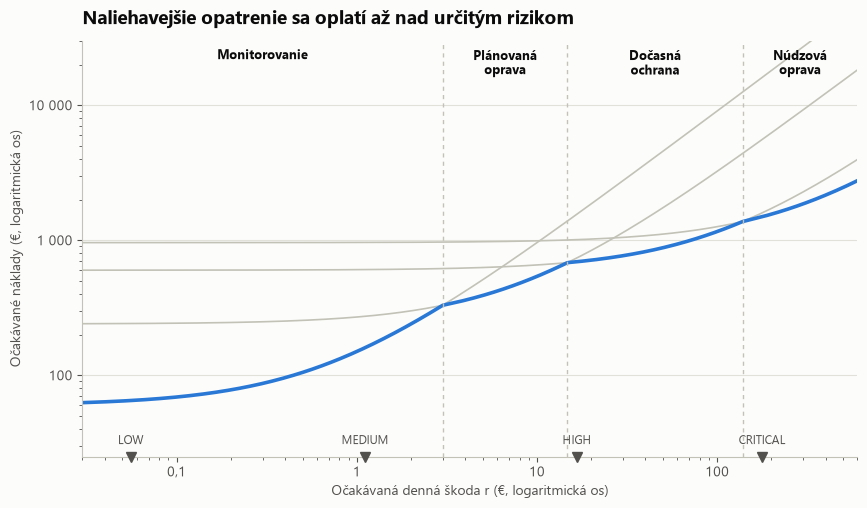

In [14]:
fig, ax = plt.subplots(figsize=(10, 5.4))
risk_grid = np.logspace(np.log10(0.03), np.log10(600), 500)
lines = COST[:, None] + EXPOSURE[:, None] * risk_grid

for line in lines:
    ax.plot(risk_grid, line, color=NEUTRAL_BAR, linewidth=1.2)
ax.plot(risk_grid, lines.min(axis=0), color=BLUE, linewidth=2.6)

edges = [risk_grid[0]] + [point[2] for point in break_even_points(COST, EXPOSURE)] + [risk_grid[-1]]
for edge in edges[1:-1]:
    ax.axvline(edge, color=AXIS, linewidth=1, linestyle=(0, (3, 3)))
for index, name in enumerate(ACTION_NAMES):
    middle = np.sqrt(edges[index] * edges[index + 1])
    ax.text(middle, 26000, name.replace(" ", "\n", 1), ha="center", va="top", color=INK, fontsize=9.5, fontweight="bold")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(risk_grid[0], risk_grid[-1])
ax.set_ylim(25, 30000)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.xaxis.set_major_formatter(lambda value, _: f"{value:g}".replace(".", ","))
ax.yaxis.set_major_formatter(lambda value, _: thousands(value))
ax.set_xlabel("Očakávaná denná škoda r (€, logaritmická os)")
ax.set_ylabel("Očakávané náklady (€, logaritmická os)")

for label, risk in zip(LABELS, DAILY_RISK):
    ax.plot([risk], [25], marker="v", color=INK_SECONDARY, markersize=7, clip_on=False, zorder=5)
    ax.annotate(label, (risk, 25), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8.5, color=INK_SECONDARY)

ax.set_title('Naliehavejšie opatrenie sa oplatí až nad určitým rizikom', loc="left", fontsize=14, fontweight="bold", pad=12)
fig.savefig(FIGURES_DIR / "7_prahy_opatreni.png")
plt.show()

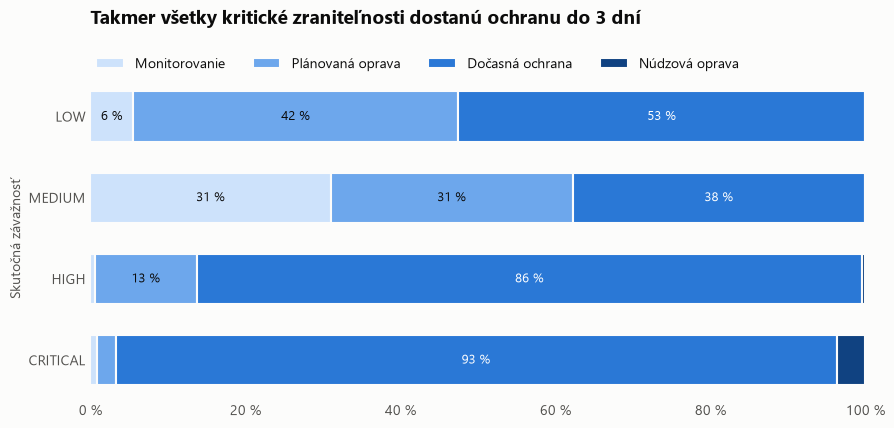

In [15]:
fig, ax = plt.subplots(figsize=(10, 4.2))
rows_order = LABELS[::-1]
left = np.zeros(4)
for index, action in enumerate(ACTION_NAMES):
    values = action_by_truth.loc[rows_order, action].to_numpy() * 100
    bars = ax.barh(rows_order, values, left=left, height=0.62, color=ACTION_COLORS[index],
                   edgecolor=SURFACE, linewidth=1.5, label=action)
    for bar, value, start in zip(bars, values, left):
        if value >= 5:
            ax.text(start + value / 2, bar.get_y() + bar.get_height() / 2, f"{value:.0f} %",
                    ha="center", va="center", color=ACTION_TEXT[index], fontsize=9.5)
    left += values

ax.spines[:].set_visible(False)
ax.tick_params(length=0)
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(lambda value, _: f"{value:.0f} %")
ax.set_ylabel("Skutočná závažnosť")
ax.set_title('Takmer všetky kritické zraniteľnosti dostanú ochranu do 3 dní', loc="left", fontsize=14, fontweight="bold", pad=38)
ax.legend(ncols=4, frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), borderaxespad=0)
fig.savefig(FIGURES_DIR / "8_opatrenia_podla_zavaznosti.png")
plt.show()

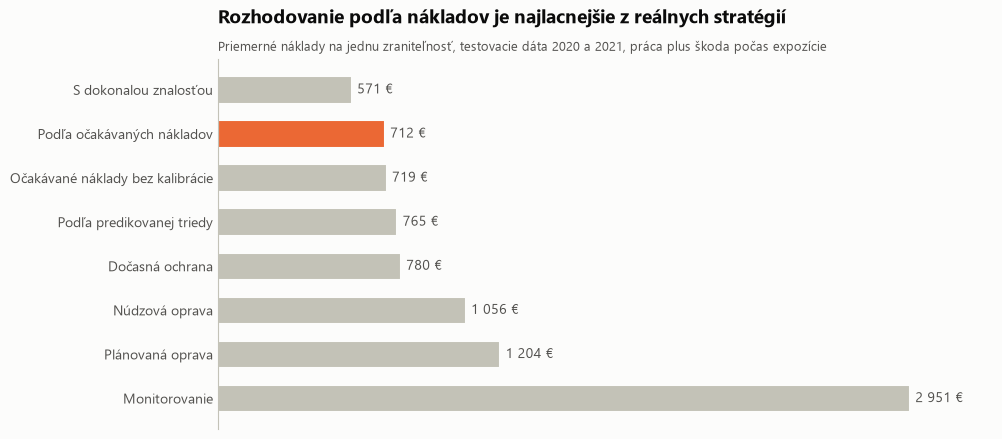

In [16]:
plot_table = comparison.sort_values("spolu (€)", ascending=False)
fig, ax = plt.subplots(figsize=(10, 4.8))
colors = [ORANGE if name == STRATEGY_OURS else NEUTRAL_BAR for name in plot_table.index]
bars = ax.barh(plot_table.index, plot_table["spolu (€)"], height=0.62, color=colors, edgecolor=SURFACE, linewidth=1.5)
ax.bar_label(bars, labels=[f"{value:,.0f} €".replace(",", " ") for value in plot_table["spolu (€)"]],
             padding=4, color=INK_SECONDARY)

ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.tick_params(length=0)
ax.xaxis.set_visible(False)
ax.set_xlim(0, plot_table["spolu (€)"].max() * 1.12)
ax.set_title('Rozhodovanie podľa nákladov je najlacnejšie z reálnych stratégií', loc="left", fontsize=14, fontweight="bold", pad=26)
ax.text(0, 1.015,"Priemerné náklady na jednu zraniteľnosť, testovacie dáta 2020 a 2021, práca plus škoda počas expozície",
        transform=ax.transAxes, color=INK_SECONDARY, fontsize=9.5, va="bottom")
fig.savefig(FIGURES_DIR / "9_porovnanie_strategii.png")
plt.show()

## 8. Uloženie odporúčaní

Súbor obsahuje každú testovaciu zraniteľnosť s odporúčaným opatrením. Záznamy sú zoradené podľa priority.

In [17]:
output = recommendations.sort_values("ocakavane_denne_riziko", ascending=False).drop(columns="description")
output.insert(0, "priorita", np.arange(1, len(output) + 1))
output.round(4).to_csv(OUTPUT_PATH, index=False, encoding="utf-8")
print(f"Uložené: {OUTPUT_PATH}, záznamy: {len(output)}")

Uložené: data\processed\odporucania_opatreni.csv, záznamy: 32050


## 9. Zhrnutie a odporúčania

Výsledky platia pre 32 050 zraniteľností z rokov 2020 a 2021. Finančné hodnoty vychádzajú z predpokladov v časti 2, preto sú dôležité najmä prahy a poradie stratégií, nie absolútne sumy.

| Opatrenie | Kedy sa použije | Podiel CVE | Skutočne `CRITICAL` | Zdôvodnenie |
| --- | --- | ---: | ---: | --- |
| **Monitorovanie** | `r` do 3,00 € za deň | 13,3 % | 0,9 % | Skoršia oprava stojí o 180 € viac a skráti expozíciu o 60 dní. Pod týmto prahom ušetrené riziko túto prácu nevynahradí. |
| **Plánovaná oprava** | `r` od 3,00 do 14,75 € za deň | 19,8 % | 1,6 % | Riziko ospravedlní opravu v bežnom cykle, no nie 360 € navyše za mimoriadny zásah. |
| **Dočasná ochrana a prioritná oprava** | `r` od 14,75 do 138,46 € za deň | 66,3 % | 19,4 % | Väčšinu rizika odstráni do 2 dní a dá sa vrátiť späť. Hodí sa, keď model signalizuje riziko, ale nie je si istý triedou. |
| **Núdzová oprava** | `r` nad 138,46 € za deň | 0,7 % | 70,4 % | Najdrahší a najrušivejší zásah. Odporúča sa, až keď je kritickosť veľmi pravdepodobná. |

**Faktory.** Rozhodnutie spája riziko (pravdepodobnosti z modelu a škoda), čas (dni expozície), náklady (hodiny práce) a prioritu (poradie vo fronte podľa `r`).

**Výsledky:**

- Rozhodovanie podľa očakávaných nákladov vyšlo na 711,5 € na zraniteľnosť. Najlepšia pevná stratégia, dočasná ochrana pre všetko, vyšla na 779,9 €.
- Úspora je 68,39 € na zraniteľnosť, teda 8,8 %, s 95 % intervalom [61,66; 74,69] €. Oproti pevnej stratégii ušetrí 140,1 € na práci a o 71,7 € zvýši škodu počas expozície.
- Oproti priamemu mapovaniu predikovanej triedy na opatrenie je úspora 53,32 €, teda 7,0 %, s 95 % intervalom [47,05; 59,54] €.
- Kalibrácia znížila log loss z 0,837 na 0,774. Finančný prínos je malý, 7,95 € na zraniteľnosť, teda 1,1 %, s 95 % intervalom [5,60; 10,26] €.
- 96,8 % skutočne kritických zraniteľností dostane ochranu alebo opravu do 3 dní. Iba monitorovaných zostane 0,9 %.
- Pri obmedzenej kapacite pokryje prvých 10 % frontu 41,3 % kritických zraniteľností a prvých 20 % až 65,0 %. To je 4,1-násobok a 3,3-násobok náhodného poradia.
- Vo všetkých scenároch citlivosti stratégia prekonala najlepšiu pevnú stratégiu, úspora bola od 4,9 % do 20,5 %. Najväčšia je pri nízkej škode alebo drahej práci, keď sa oplatí triediť prísnejšie.

**Odporúčanie.** Nasadiť rozhodovanie podľa očakávaných nákladov ako prvotné triedenie nových zraniteľností a rozhodnutia v pásme núdzovej opravy nechať potvrdiť analytikom. Model často nedokáže odlíšiť `HIGH` od `CRITICAL`, preto je kľúčovým opatrením rýchla a vratná dočasná ochrana.

**Obmedzenia:**

- Náklady, časy a pravdepodobnosti zneužitia sú predpoklady, nie merania. Na mixe opatrení záleží iba pomer škody a ceny práce, preto scenáre *Škoda × 2* a *Práca × 0,5* dávajú rovnaké rozhodnutia.
- Dataset neobsahuje kontext organizácie. Každá zraniteľnosť sa posudzuje, akoby sa týkala rovnako hodnotného aktíva vystaveného rovnakému riziku. Pri nasadení treba zahrnúť inventár aktív, dostupnosť zo siete a údaje o zneužívaní, napríklad EPSS a CISA KEV.
- Kapacita nie je v rozhodovaní tvrdo obmedzená. Dočasná ochrana pre 21 237 zraniteľností by znamenala 212 370 hodín práce, čo je realistické len po odfiltrovaní zraniteľností, ktoré sa organizácie netýkajú.
- Postup minimalizuje priemerné náklady. Organizácia, ktorá sa chce vyhnúť zriedkavým veľkým škodám, by mala prahy znížiť.
- Na testovacích dátach kalibrácia mierne nadhodnocuje riziko, napríklad v pásme `P(CRITICAL)` od 0,2 do 0,3 je priemerný odhad 0,247 a skutočný podiel 0,188. Podiel `CRITICAL` medzi rokom 2019 a testom klesol zo 16,0 % na 13,8 %, preto treba kalibráciu pravidelne obnovovať.
- Model je učený iba na dátach do roku 2018, takže nie je totožný s finálnym modelom z `predikcia.ipynb`. Rok 2019 sa použil na výber jeho parametrov aj na kalibráciu.